# Lab01 - sprint 1

## Random Variables: Raman Spectral Intensities

## Description

In [ ]:
При повторных измерениях одного и того же состава интенсивности могут различаться из-за погрешности лабораторного 
прибора (спектрофотометра), из за человеческого фактора, так как люди сколонны совершать ошибки в точных измерениях 
(при подготовке пробы, при настройке прибора). При разных измерениях температура в комнате может быть разной, 
образец может быть загрязнен.Так же величина случайна, так как состав раствора разный, это влияет напрямую на 
интенсивность, поэтому мы исследуем как различия между составами, так и вариации между повторами.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

base_url = (
    "https://raw.githubusercontent.com/"
    "Alvaro-FG/Raman_Sugars/main/"
)

spectra = pd.read_csv(
    base_url + "Sugar_Concentration_Test_ALL_spectra.csv"
)

metadata = pd.read_csv(
    base_url + "Sugar_Concentration_Test_ALL_metadata.csv"
)

print("Размер таблицы спектров:", spectra.shape)
print("Размер таблицы метаданных:", metadata.shape)

print("\nСтолбцы метаданных:")
print(metadata.columns.tolist())

print("\nПервые строки метаданных:")
print(metadata.head())

print("\nПервые строки спектров:")
print(spectra.iloc[:5, :5])

Размер таблицы спектров: (2000, 1961)
Размер таблицы метаданных: (1960, 14)

Столбцы метаданных:
['samp', 'row', 'col', 'plate', 'round', 'meas', 'rep', 'filename', 'Sucrose [ul]', 'Fructose [ul]', 'Maltose [ul]', 'Glucose [ul]', 'Water [ul]', 'Total Volume [ul]']

Первые строки метаданных:
   samp row  col  plate  round  meas  rep  \
0    54   E    6      2      2     1    1   
1    43   D    7      3      2     1    2   
2    35   C   11      2      2     1    4   
3    10   A   10      1      1     1    3   
4    94   H   10      1      2     1    1   

                                      filename  Sucrose [ul]  Fructose [ul]  \
0   Sugar_Concentration_Test_54_E6_2_RD2_M1_R1            30             30   
1   Sugar_Concentration_Test_43_D7_3_RD2_M1_R2             0              0   
2  Sugar_Concentration_Test_35_C11_2_RD2_M1_R4            30             75   
3  Sugar_Concentration_Test_10_A10_1_RD1_M1_R3           120            120   
4  Sugar_Concentration_Test_94_H10_1_RD2_M

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Частоты спектра
wavenumbers = spectra["Wavenumber [cm-1]"].to_numpy()

# Ищем ближайшую измеренную частоту к каждой целевой
targets = [500, 1000, 1400]
selected_indices = [
    np.abs(wavenumbers - target).argmin()
    for target in targets
]

for target, idx in zip(targets, selected_indices):
    print(
        f"Целевая частота: {target} см⁻¹; "
        f"фактическая: {wavenumbers[idx]:.2f} см⁻¹"
    )

Целевая частота: 500 см⁻¹; фактическая: 500.33 см⁻¹
Целевая частота: 1000 см⁻¹; фактическая: 998.80 см⁻¹
Целевая частота: 1400 см⁻¹; фактическая: 1399.34 см⁻¹


Получаем интенсивности на трех выбранных частотах (для наглядности мы выводим только 9 строк, на самом же деле их очевидно, что гораздо больше):

In [4]:
X = spectra.iloc[selected_indices, 1:].T.copy()

X.columns = ["X1", "X2", "X3"]
X = X.reset_index(drop=True)

# Добавляем метаданные: состав смеси и номер повторения
data = pd.concat(
    [metadata.reset_index(drop=True), X],
    axis=1
)

print("Размер итоговой таблицы:", data.shape)
print("\nПервые строки:")
print(data[[
    "Sucrose [ul]", "Fructose [ul]",
    "Maltose [ul]", "Glucose [ul]",
    "X1", "X2", "X3"
]].head(9))

print("\nОписательная статистика:")
print(data[["X1", "X2", "X3"]].describe().round(2))

Размер итоговой таблицы: (1960, 17)

Первые строки:
   Sucrose [ul]  Fructose [ul]  Maltose [ul]  Glucose [ul]      X1      X2  \
0            30             30            75           120  3951.0  1693.0   
1             0              0            30            75  3120.0  1452.0   
2            30             75           120            75  3994.0  1760.0   
3           120            120             0             0  3505.0  1657.0   
4            75             30            30             0  2999.0  1456.0   
5             0             30            75            75  3439.0  1586.0   
6            75              0            75           120  4170.0  1799.0   
7             0            120           120           120  4240.0  1775.0   
8            30             75            75             0  3253.0  1568.0   

       X3  
0  1579.0  
1  1225.0  
2  1823.0  
3  1544.0  
4  1349.0  
5  1520.0  
6  1713.0  
7  1784.0  
8  1486.0  

Описательная статистика:
            X1       

## Random Variable 01 (X1 - интенсивность на длине волны 500.33 cm⁻¹)


### EDA, Distribution

#### Визуализация и описательные статистики

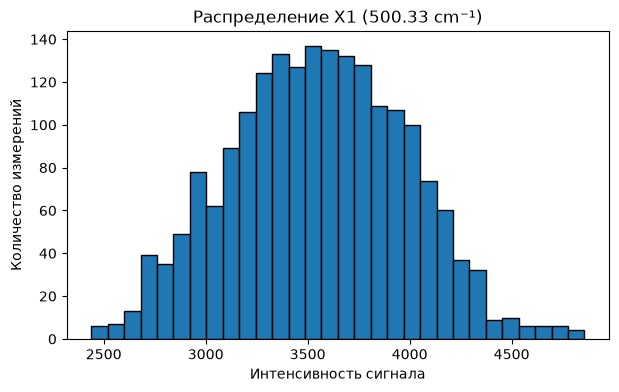

In [11]:
plt.figure(figsize=(7, 4))

plt.hist(data["X1"], bins=30, edgecolor="black")
plt.title("Распределение X1 (500.33 cm⁻¹)")
plt.xlabel("Интенсивность сигнала")
plt.ylabel("Количество измерений")

plt.show()

In [17]:
print("Медиана X1:", data["X1"].median())
print("Мода X1:", data["X1"].mode().tolist())

Медиана X1: 3556.0
Мода X1: [3251.0, 3298.0, 3736.0]


In [14]:
print("Асимметрия X1:", round(data["X1"].skew(), 3))
print("Эксцесс X1:", round(data["X1"].kurt(), 3))

Асимметрия X1: 0.048
Эксцесс X1: -0.353


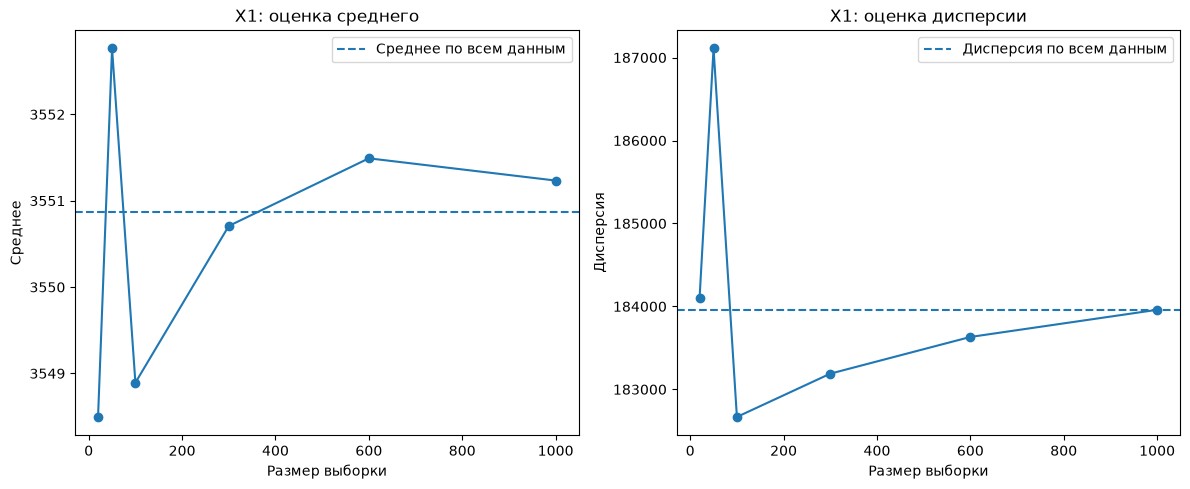

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Среднее
axes[0].plot(
    summary.index,
    summary["mean_estimate"],
    marker="o"
)
axes[0].axhline(
    true_mean,
    linestyle="--",
    label="Среднее по всем данным"
)
axes[0].set_title("X1: оценка среднего")
axes[0].set_xlabel("Размер выборки")
axes[0].set_ylabel("Среднее")
axes[0].legend()

# Дисперсия
axes[1].plot(
    summary.index,
    summary["variance_estimate"],
    marker="o"
)
axes[1].axhline(
    true_variance,
    linestyle="--",
    label="Дисперсия по всем данным"
)
axes[1].set_title("X1: оценка дисперсии")
axes[1].set_xlabel("Размер выборки")
axes[1].set_ylabel("Дисперсия")
axes[1].legend()

plt.tight_layout()
plt.show()

### Стандартизация

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

data["Z1"] = scaler.fit_transform(
    data[["X1"]]
)

print(data[["X1", "Z1"]].describe().round(3))

             X1        Z1
count  1960.000  1960.000
mean   3550.865     0.000
std     428.902     1.000
min    2439.000    -2.593
25%    3247.000    -0.709
50%    3556.000     0.012
75%    3862.000     0.726
max    4857.000     3.046


#### Математическая база распределения и его особенности

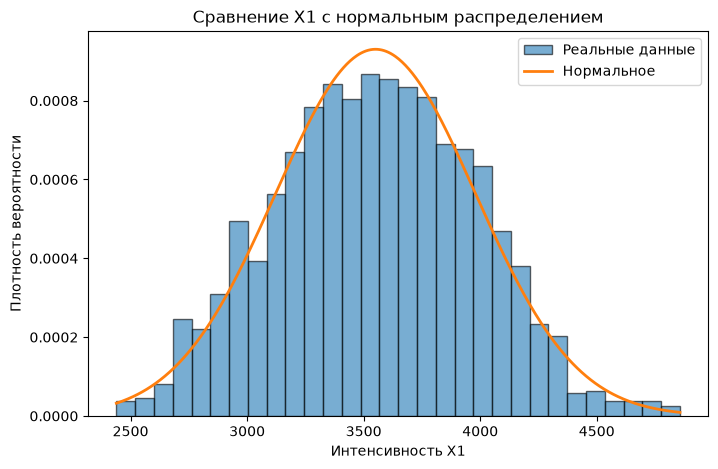

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

X1 = data["X1"].dropna()

mu = X1.mean()
sigma = X1.std(ddof=0)

x = np.linspace(X1.min(), X1.max(), 500)
y = norm.pdf(x, mu, sigma)

plt.figure(figsize=(8, 5))

plt.hist(
    X1,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Реальные данные"
)

plt.plot(
    x,
    y,
    linewidth=2,
    label="Нормальное"
)

plt.title("Сравнение X1 с нормальным распределением")
plt.xlabel("Интенсивность X1")
plt.ylabel("Плотность вероятности")
plt.legend()
plt.show()

#### Проверка гипотезы о нормальности с помощью статистического критерия

In [27]:
from scipy.stats import shapiro

X1 = data["X1"].dropna()

sample_test = X1.sample(n=500, random_state=42)

statistic, p_value = shapiro(sample_test)

alpha = 0.05

print("Гипотеза 1: нормальность распределения X1")
print(f"Статистика Шапиро - Уилка: {statistic:.4f}")
print(f"p-value: {p_value:.6g}")

if p_value < alpha:
    print("Решение: отвергаем H0.")
    print("Есть статистические свидетельства против нормальности.")
else:
    print("Решение: нет оснований отвергнуть H0.")
    print("Данных недостаточно, чтобы заключить, что распределение ненормальное.")

Гипотеза 1: нормальность распределения X1
Статистика Шапиро - Уилка: 0.9945
p-value: 0.0710418
Решение: нет оснований отвергнуть H0.
Данных недостаточно, чтобы заключить, что распределение ненормальное.


In [28]:

from scipy.stats import pearsonr

# Выбираем два столбца и удаляем строки с пропущенными значениями
paired = data[["X2", "X3"]].dropna()

# Проверяем линейную корреляцию Пирсона
r, p_value = pearsonr(paired["X2"], paired["X3"])

alpha = 0.05

print("Гипотеза 2: линейная связь между X2 и X3")
print(f"Число наблюдений: {len(paired)}")
print(f"Коэффициент корреляции Пирсона: {r:.4f}")
print(f"p-value: {p_value:.6g}")

if p_value < alpha:
    print("Решение: отвергаем H0.")
    print("Линейная связь статистически значима.")
else:
    print("Решение: нет оснований отвергнуть H0.")
    print("Статистически значимая линейная связь не установлена.")


Гипотеза 2: линейная связь между X2 и X3
Число наблюдений: 1960
Коэффициент корреляции Пирсона: 0.9629
p-value: 0
Решение: отвергаем H0.
Линейная связь статистически значима.


### Independence & Estimations

In [18]:
print("Корреляция Пирсона:")
print(data[["X1", "X2", "X3"]].corr().round(3))

Корреляция Пирсона:
       X1     X2     X3
X1  1.000  0.885  0.877
X2  0.885  1.000  0.963
X3  0.877  0.963  1.000


In [19]:
spearman_corr = data[["X1", "X2", "X3"]].corr(method="spearman")

print("\nКорреляция Спирмена:")
print(spearman_corr.round(3))


Корреляция Спирмена:
       X1     X2     X3
X1  1.000  0.891  0.885
X2  0.891  1.000  0.965
X3  0.885  0.965  1.000


In [20]:
sugar_columns = [
    "Sucrose [ul]",
    "Fructose [ul]",
    "Maltose [ul]",
    "Glucose [ul]",
    "Water [ul]"
]

variables = ["X1", "X2", "X3"]

# Средняя интенсивность для каждого состава
composition_means = data.groupby(
    sugar_columns
)[variables].transform("mean")

# Отклонения каждого измерения от среднего своего состава
residuals = data[variables] - composition_means

print("Корреляция отклонений от среднего состава:")
print(residuals.corr().round(3))

print("\nСтандартные отклонения исходных интенсивностей:")
print(data[variables].std().round(2))

print("\nСтандартные отклонения отклонений внутри состава:")
print(residuals.std().round(2))


Корреляция отклонений от среднего состава:
       X1     X2     X3
X1  1.000  0.077  0.050
X2  0.077  1.000  0.068
X3  0.050  0.068  1.000

Стандартные отклонения исходных интенсивностей:
X1    428.90
X2    148.83
X3    233.30
dtype: float64

Стандартные отклонения отклонений внутри состава:
X1    46.05
X2    26.50
X3    35.56
dtype: float64


In [ ]:
Определим для величины 1 состоятельность оценок

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X1 = data["X1"]

# Характеристики всех 1960 измерений - ориентиры
true_mean = X1.mean()
true_variance = X1.var(ddof=1)

print(f"Среднее по всем данным: {true_mean:.2f}")
print(f"Дисперсия по всем данным: {true_variance:.2f}")

# Размеры выборок
sample_sizes = [20, 50, 100, 300, 600, 1000]
n_repeats = 500

rng = np.random.default_rng(42)
results = []

# Многократный случайный отбор без возвращения
for n in sample_sizes:
    for _ in range(n_repeats):
        sample = X1.sample(
            n=n,
            replace=False,
            random_state=int(rng.integers(0, 2**31))
        )

        results.append({
            "n": n,
            "mean": sample.mean(),
            "variance": sample.var(ddof=1)
        })

results = pd.DataFrame(results)

summary = results.groupby("n").agg(
    mean_estimate=("mean", "mean"),
    mean_sd=("mean", "std"),
    variance_estimate=("variance", "mean"),
    variance_sd=("variance", "std")
)

print("\nРезультаты:")
print(summary.round(2))

Среднее по всем данным: 3550.86
Дисперсия по всем данным: 183956.79

Результаты:
      mean_estimate  mean_sd  variance_estimate  variance_sd
n                                                           
20          3548.50    93.33          184096.51     54367.38
50          3552.76    60.33          187110.21     33687.18
100         3548.89    40.66          182667.17     23053.28
300         3550.71    21.87          183189.03     12322.17
600         3551.49    15.28          183631.52      8576.39
1000        3551.23     9.43          183958.95      4966.56


In [23]:
# Размеры выборок
sample_sizes = [20, 50, 100, 300, 600, 1000]
n_repeats = 500

results_with = []

# Многократный случайный отбор с возвращением
for n in sample_sizes:
    for _ in range(n_repeats):
        sample = X1.sample(
            n=n,
            replace=True,
            random_state=int(rng.integers(0, 2**31))
        )

        results_with.append({
            "n": n,
            "mean": sample.mean(),
            "variance": sample.var(ddof=1)
        })

results_with = pd.DataFrame(results_with)

# Сводная таблица
summary_with = results_with.groupby("n").agg(
    mean_estimate=("mean", "mean"),
    mean_sd=("mean", "std"),
    variance_estimate=("variance", "mean"),
    variance_sd=("variance", "std")
)

print("Результаты с возвращением:")
print(summary_with.round(2))

Результаты с возвращением:
      mean_estimate  mean_sd  variance_estimate  variance_sd
n                                                           
20          3559.05   100.09          183365.42     53865.43
50          3549.10    62.43          183382.61     32417.50
100         3548.73    43.20          183797.94     23629.73
300         3551.04    24.38          184974.67     13934.51
600         3549.12    17.34          183456.12      9654.61
1000        3550.52    14.28          184008.01      7476.21
